# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 : Nicolas Duclos
- Alumno 2 : Damian Grimaldi

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [1]:
# TO-DO: completar con la URL de tu fork.
# Repo privado: https://<TOKEN>@github.com/<usuario>/tuia-dog-recognition-app.git
#REPO_URL = "https://github.com/<usuario>/tuia-dog-recognition-app.git"

#!git clone $REPO_URL proyecto
#%cd proyecto

## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [2]:
#!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

In [2]:
import os
import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch

# Detectar raiz del proyecto independientemente de si Jupyter se lanza en / o /notebooks
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

os.environ.setdefault("USE_PGVECTOR", "false")

from lib.config import settings
from lib.preprocessing import (
    IMAGENET_MEAN,
    IMAGENET_STD,
    normalize_breed_name,
    bgr_to_rgb,
    get_eval_transforms,
    get_train_transforms,
    get_visual_augmentation_pipeline,
    preprocess_bgr_image,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATASET_DIR = (
    settings.dataset_path
    if settings.dataset_path.is_absolute()
    else ROOT / settings.dataset_path
)
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"ROOT        : {ROOT}")
print(f"DATASET_DIR : {DATASET_DIR} (existe={DATASET_DIR.exists()})")
print(f"IMAGE_SIZE  : {settings.image_size}")
print(f"GPU CUDA    : {torch.cuda.is_available()}")

c:\Users\nicod\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT        : c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app
DATASET_DIR : c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset (existe=True)
IMAGE_SIZE  : 224
GPU CUDA    : False


## 4. Descargar el dataset

In [4]:
!python scripts/download_dataset.py
#!ls data/dataset

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Ya existe, se omite: C:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset\dogs.csv
Ya existe, se omite: C:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset\test
Ya existe, se omite: C:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset\train
Ya existe, se omite: C:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset\valid
Dataset disponible en C:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\dataset


## 5. Descripción del dataset

In [6]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def scan_dataset(dataset_dir: Path) -> pd.DataFrame:
    records = []
    for split in ["train", "valid", "test"]:
        split_dir = dataset_dir / split
        if not split_dir.exists():
            continue
        for breed_dir in sorted(split_dir.iterdir()):
            if not breed_dir.is_dir():
                continue
            raw_breed = breed_dir.name
            breed = normalize_breed_name(raw_breed)
            for img_path in sorted(breed_dir.iterdir()):
                if img_path.is_file() and img_path.suffix.lower() in IMAGE_EXTS:
                    records.append(
                        {
                            "split": split,
                            "raw_breed_dir": raw_breed,
                            "breed": breed,
                            "filepath": str(img_path),
                            "rel_path": img_path.relative_to(DATA_DIR).as_posix(),
                            "ext": img_path.suffix.lower(),
                        }
                    )
    return pd.DataFrame(records)


df_raw = scan_dataset(DATASET_DIR)

# Verificar discrepancia de nombres de carpetas entre splits
dir_mismatches = df_raw[df_raw["raw_breed_dir"] != df_raw["breed"]][
    ["split", "raw_breed_dir", "breed"]
].drop_duplicates()
print("Carpetas con espacios irregulares:")
display(dir_mismatches)

summary_raw = (
    df_raw.groupby(["split", "breed"])
    .size()
    .unstack(fill_value=0)
    .reindex(["train", "valid", "test"])
)
print(f"\nTotal de razas normalizadas: {summary_raw.shape[1]}")
print("Total de imágenes por split:", df_raw["split"].value_counts().to_dict())
display(summary_raw.T.describe().round(2))

Carpetas con espacios irregulares:


,split,raw_breed_dir,breed
7976,valid,American Spaniel,American Spaniel



Total de razas normalizadas: 70
Total de imágenes por split: {'train': 7946, 'valid': 700, 'test': 700}


split,train,valid,test
count,70.00,70.0,70.0
mean,113.51,10.0,10.0
std,24.68,0.0,0.0
min,65.00,10.0,10.0
25%,99.00,10.0,10.0
50%,111.50,10.0,10.0
75%,125.00,10.0,10.0
max,198.00,10.0,10.0



- **Origen y licencia:** *70 Dog Breeds Image Dataset* (Kaggle, `gpiosenka/70-dog-breedsimage-data-set`).
- **Estructura y volumen:** Contiene **70 clases** divididas originalmente en tres particiones (`train`, `valid`, `test`), en formato **JPEG** de 3 canales (RGB) y resolución estándar de **224 × 224 píxeles**.
- **Error en el nombre de una carpeta:** En la partición `valid`, la clase `American  Spaniel` contiene un doble espacio en el nombre del directorio respecto de `train/American Spaniel` y `test/American Spaniel`.
- **Comparación de encuadre con la Etapa 3 (YOLO):** Las imágenes del dataset son retratos centrados donde el animal ocupa la mayor parte del cuadro, con fondos relativamente limpios o desenfocados. En cambio, en la Etapa 3 (`DetectionService`), el clasificador recibirá recortes (`crop`) generados por las *bounding boxes* de YOLO sobre escenas reales: estos recortes pueden tener relaciones de aspecto diversas, márgenes de fondo, oclusiones parciales o múltiples perros cercanos.
- **Limitaciones y sesgos:**
  1. *Razas visualmente muy similares:* pares como `Cocker` / `American Spaniel` / `Blenheim`, `Labrador` / `Golden Retriever`, `Siberian Husky` / `Elk Hound` / `Coyote`, o `Bull Terrier` / `Pit Bull` presentan alta similitud inter-clase.
  2. *Cánidos silvestres mezclados con razas domésticas:* el dataset incluye `African Wild Dog`, `Coyote`, `Dhole` y `Dingo`.
  3. *Sesgo de fotografía de exposición/estudio:* predominan poses frontales y buena iluminación, lo que puede degradar el desempeño frente a fotos caseras con poca luz o ángulos extremos.

## 6. Análisis exploratorio (EDA)

- Distribución de clases: imágenes por raza en cada split (gráfico y estadísticas). Desbalance.
- Resoluciones, relación de aspecto, canales, formatos y archivos corruptos.
- Grilla de ejemplos por raza, incluyendo pares de razas fáciles de confundir.

Train por raza -> min: 65 (American Hairless), max: 198 (Shih-Tzu), ratio desbalance: 3.05x
Valid por raza -> min: 10, max: 10
Test  por raza -> min: 10, max: 10


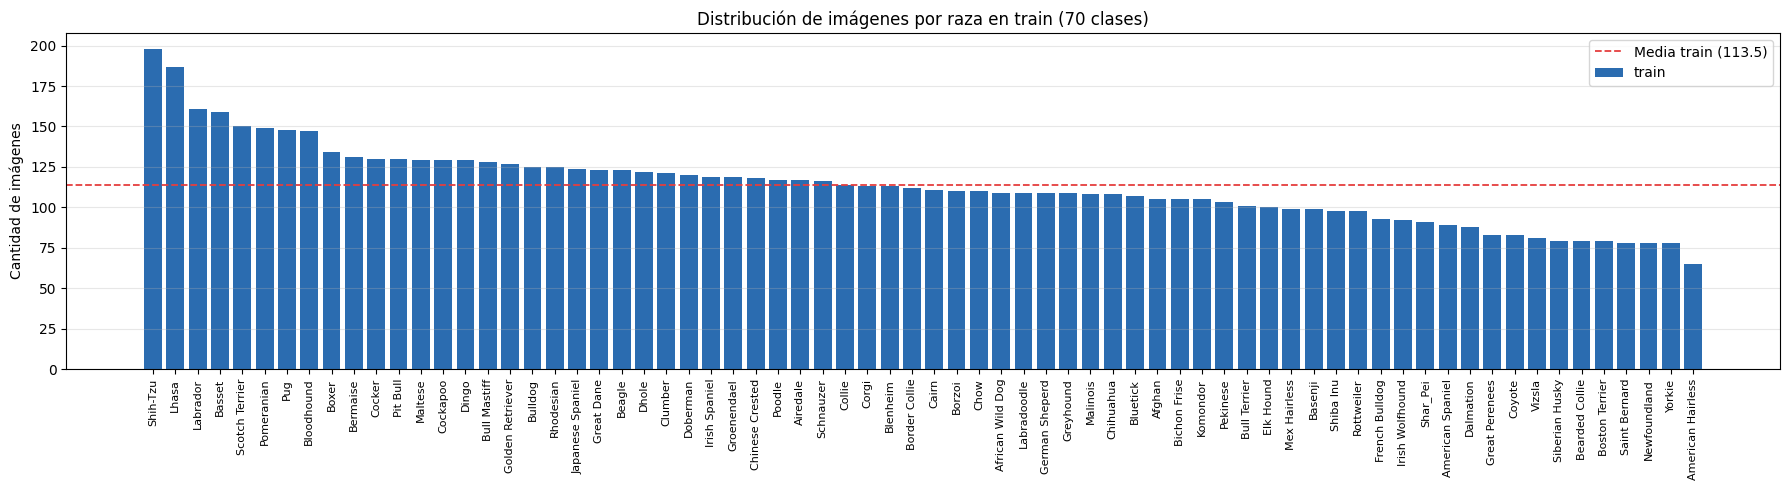

In [7]:
# 1. Distribución de imágenes por raza y split
counts_per_split = (
    df_raw.groupby(["breed", "split"]).size().unstack(fill_value=0)[["train", "valid", "test"]]
)
counts_sorted = counts_per_split.sort_values("train", ascending=False)

train_min, train_max = counts_sorted["train"].min(), counts_sorted["train"].max()
imbalance_ratio = train_max / max(train_min, 1)
print(
    f"Train por raza -> min: {train_min} ({counts_sorted['train'].idxmin()}), "
    f"max: {train_max} ({counts_sorted['train'].idxmax()}), "
    f"ratio desbalance: {imbalance_ratio:.2f}x"
)
print(f"Valid por raza -> min: {counts_sorted['valid'].min()}, max: {counts_sorted['valid'].max()}")
print(f"Test  por raza -> min: {counts_sorted['test'].min()}, max: {counts_sorted['test'].max()}")

fig, ax = plt.subplots(figsize=(18, 5))
x = np.arange(len(counts_sorted))
ax.bar(x, counts_sorted["train"], width=0.8, label="train", color="#2b6cb0")
ax.axhline(
    counts_sorted["train"].mean(),
    color="#e53e3e",
    linestyle="--",
    linewidth=1.3,
    label=f"Media train ({counts_sorted['train'].mean():.1f})",
)
ax.set_xticks(x)
ax.set_xticklabels(counts_sorted.index, rotation=90, fontsize=8)
ax.set_ylabel("Cantidad de imágenes")
ax.set_title("Distribución de imágenes por raza en train (70 clases)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
import hashlib


def inspect_image_row(filepath: str) -> dict:
    path = Path(filepath)
    try:
        raw_bytes = path.read_bytes()
        sha256 = hashlib.sha256(raw_bytes).hexdigest()
    except Exception:
        return {"corrupt": True}

    img = cv2.imread(filepath, cv2.IMREAD_UNCHANGED)
    if img is None or img.size == 0:
        return {"corrupt": True, "sha256": sha256}

    h, w = img.shape[:2]
    channels = 1 if img.ndim == 2 else img.shape[2]
    bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR) if channels == 1 else img[:, :, :3]
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

    blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    brightness = float(gray.mean())
    contrast = float(gray.std())

    # dHash 8x8 para detección de casi-duplicados
    resized_hash = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA)
    diff = resized_hash[:, 1:] > resized_hash[:, :-1]
    dhash_int = int(sum(1 << idx for idx, val in enumerate(diff.flatten()) if val))

    return {
        "corrupt": False,
        "width": int(w),
        "height": int(h),
        "aspect_ratio": round(w / max(h, 1), 3),
        "channels": int(channels),
        "blur_score": blur_score,
        "brightness": brightness,
        "contrast": contrast,
        "mean_r": float(rgb[:, :, 0].mean()),
        "mean_g": float(rgb[:, :, 1].mean()),
        "mean_b": float(rgb[:, :, 2].mean()),
        "std_r": float(rgb[:, :, 0].std()),
        "std_g": float(rgb[:, :, 1].std()),
        "std_b": float(rgb[:, :, 2].std()),
        "sha256": sha256,
        "dhash": dhash_int,
    }


meta_df = pd.DataFrame([inspect_image_row(fp) for fp in df_raw["filepath"]])
df_eda = pd.concat([df_raw.reset_index(drop=True), meta_df], axis=1)

valid_eda = df_eda[~df_eda["corrupt"]]
print("Archivos corruptos detectados:", int(df_eda["corrupt"].sum()))
print("Resoluciones únicas (width x height):")
print(valid_eda.groupby(["width", "height"]).size().sort_values(ascending=False).head(10))
print("\nCantidad de canales:", valid_eda["channels"].value_counts().to_dict())
print("Formatos:", valid_eda["ext"].value_counts().to_dict())

train_stats = valid_eda[valid_eda["split"] == "train"]
print(
    f"\nEstadísticas empíricas RGB en train -> "
    f"mean=({train_stats['mean_r'].mean():.3f}, {train_stats['mean_g'].mean():.3f}, {train_stats['mean_b'].mean():.3f}), "
    f"std=({train_stats['std_r'].mean():.3f}, {train_stats['std_g'].mean():.3f}, {train_stats['std_b'].mean():.3f})"
)
print(f"Estadísticas ImageNet referencia     -> mean={IMAGENET_MEAN}, std={IMAGENET_STD}")

Archivos corruptos detectados: 0
Resoluciones únicas (width x height):
width  height
224    224       9346
dtype: int64

Cantidad de canales: {3: 9346}
Formatos: {'.jpg': 9346}

Estadísticas empíricas RGB en train -> mean=(0.526, 0.490, 0.422), std=(0.232, 0.231, 0.232)
Estadísticas ImageNet referencia     -> mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)


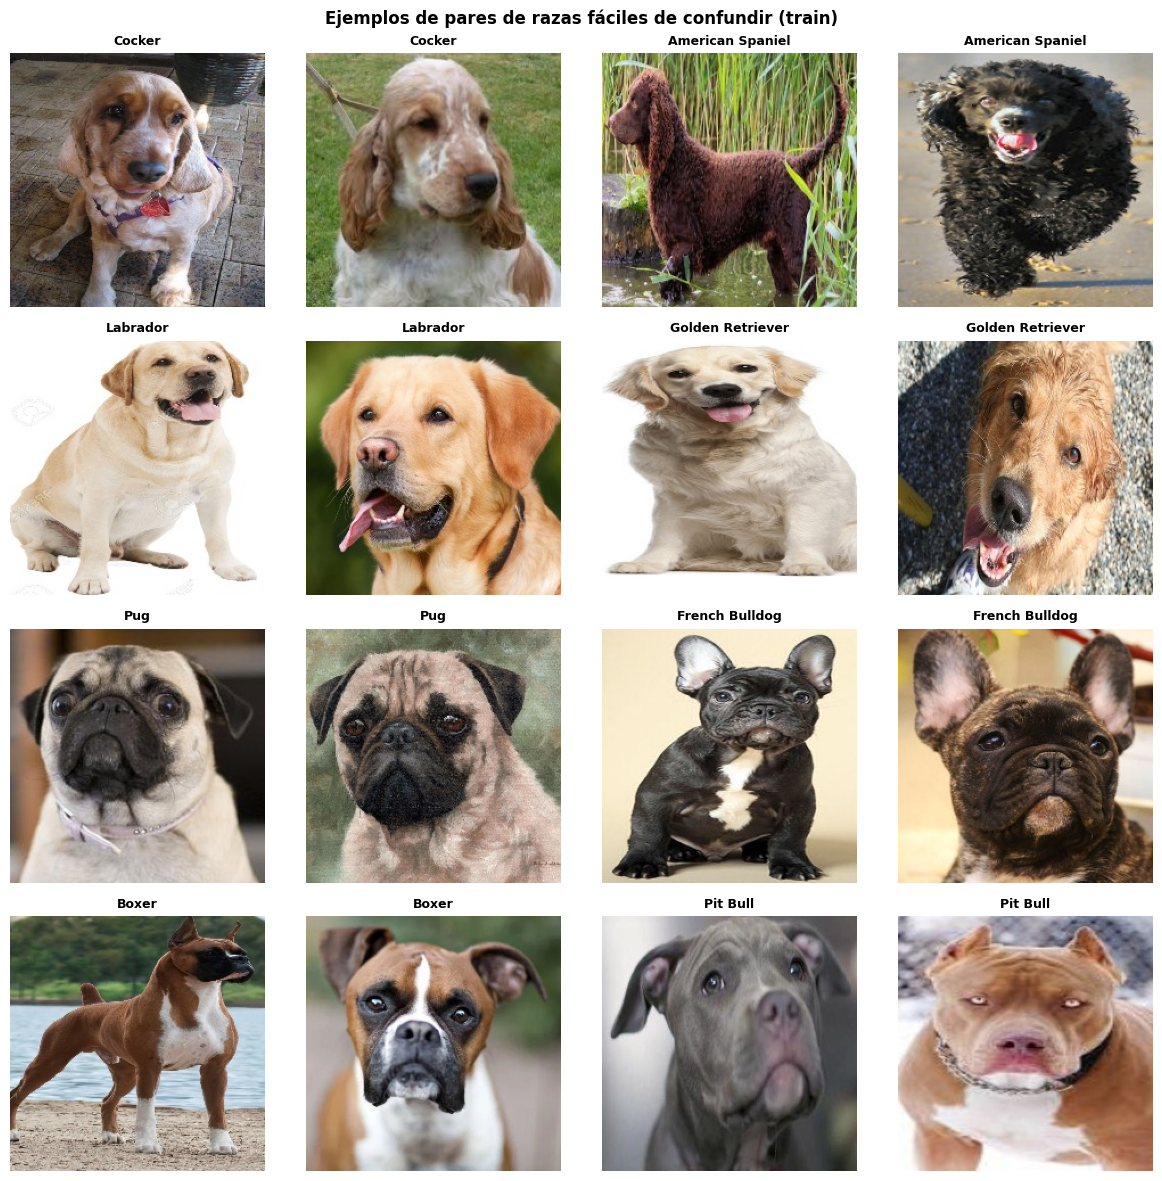

Distribución de perros detectados por imagen (muestra de 140 imágenes, conf=0.25):
  0 perro(s): 57 imágenes (40.7%)
  1 perro(s): 82 imágenes (58.6%)
  2 perro(s): 1 imágenes (0.7%)


In [9]:
# Grilla de pares de razas visualmente similares
confused_pairs = [
    ("Cocker", "American Spaniel"),
    ("Labrador", "Golden Retriever"),
    ("Pug", "French Bulldog"),
    ("Boxer", "Pit Bull"),
]

fig, axes = plt.subplots(len(confused_pairs), 4, figsize=(12, 3 * len(confused_pairs)))
for row_idx, (breed_a, breed_b) in enumerate(confused_pairs):
    samples_a = valid_eda[(valid_eda["split"] == "train") & (valid_eda["breed"] == breed_a)].sample(
        2, random_state=SEED
    )
    samples_b = valid_eda[(valid_eda["split"] == "train") & (valid_eda["breed"] == breed_b)].sample(
        2, random_state=SEED
    )
    row_samples = pd.concat([samples_a, samples_b])
    for col_idx, (_, r) in enumerate(row_samples.iterrows()):
        img_rgb = bgr_to_rgb(cv2.imread(r["filepath"]))
        axes[row_idx, col_idx].imshow(img_rgb)
        axes[row_idx, col_idx].set_title(r["breed"], fontsize=9, fontweight="bold")
        axes[row_idx, col_idx].axis("off")

plt.suptitle("Ejemplos de pares de razas fáciles de confundir (train)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Muestreo con YOLOv8n para estimar cantidad de perros por imagen en el dataset
from ultralytics import YOLO

yolo_eda = YOLO(settings.yolo_model)
sample_paths = valid_eda.sample(n=min(140, len(valid_eda)), random_state=SEED)["filepath"].tolist()
dog_counts = []
for p in sample_paths:
    res = yolo_eda.predict(p, conf=0.25, classes=[settings.yolo_dog_class_id], verbose=False)[0]
    dog_counts.append(len(res.boxes))

vc_dogs = pd.Series(dog_counts).value_counts().sort_index()
print("Distribución de perros detectados por imagen (muestra de 140 imágenes, conf=0.25):")
for n_dogs, cnt in vc_dogs.items():
    print(f"  {n_dogs} perro(s): {cnt} imágenes ({100 * cnt / len(dog_counts):.1f}%)")

## 7. Control de calidad y filtrado

Se definen 5 reglas explícitas y reproducibles sobre todo el dataset (`train`, `valid`, `test`):

1. **R1 — Archivos corruptos o ilegibles:** imágenes que `cv2.imread` no logra decodificar o tienen tamaño nulo.
2. **R2 — Resolución o proporción extrema:** imágenes con lado mínimo `< 64 px` o relación de aspecto fuera de `[0.25, 4.0]`.
3. **R3 — Exposición extrema o imagen uniforme:** brillo medio `< 15` (subexpuesta/negra), `> 245` (quemada/blanca) o desvío estándar en escala de grises `< 8.0`.
4. **R4 — Desenfoque severo (blur):** varianza del Laplaciano `< 15.0` (umbral conservador para descartar únicamente imágenes severamente fuera de foco sin penalizar retratos con *bokeh* en el fondo).
5. **R5 — Duplicados exactos y casi-duplicados (con prevención de fuga entre splits):**
   - Duplicados exactos por hash `SHA-256` o casi-duplicados perceptuales (`dHash` de 64 bits con distancia de Hamming `<= 3`).
   - Prioridad de conservación para evitar *data leakage*: **`test` > `valid` > `train`**. Si una imagen en `train` es duplicada o casi-duplicada de una en `valid` o `test`, se descarta la copia de `train` para garantizar que validación y prueba permanezcan intactos y libres de fuga.

Total imágenes analizadas : 9346
Total imágenes descartadas: 233
Total imágenes conservadas: 9113


split,test,train,valid,Total
discard_reason,,,,
R5_cross_split_near_dup,0,25,4,29
R5_exact_duplicate,4,106,7,117
R5_within_split_near_dup,0,85,2,87


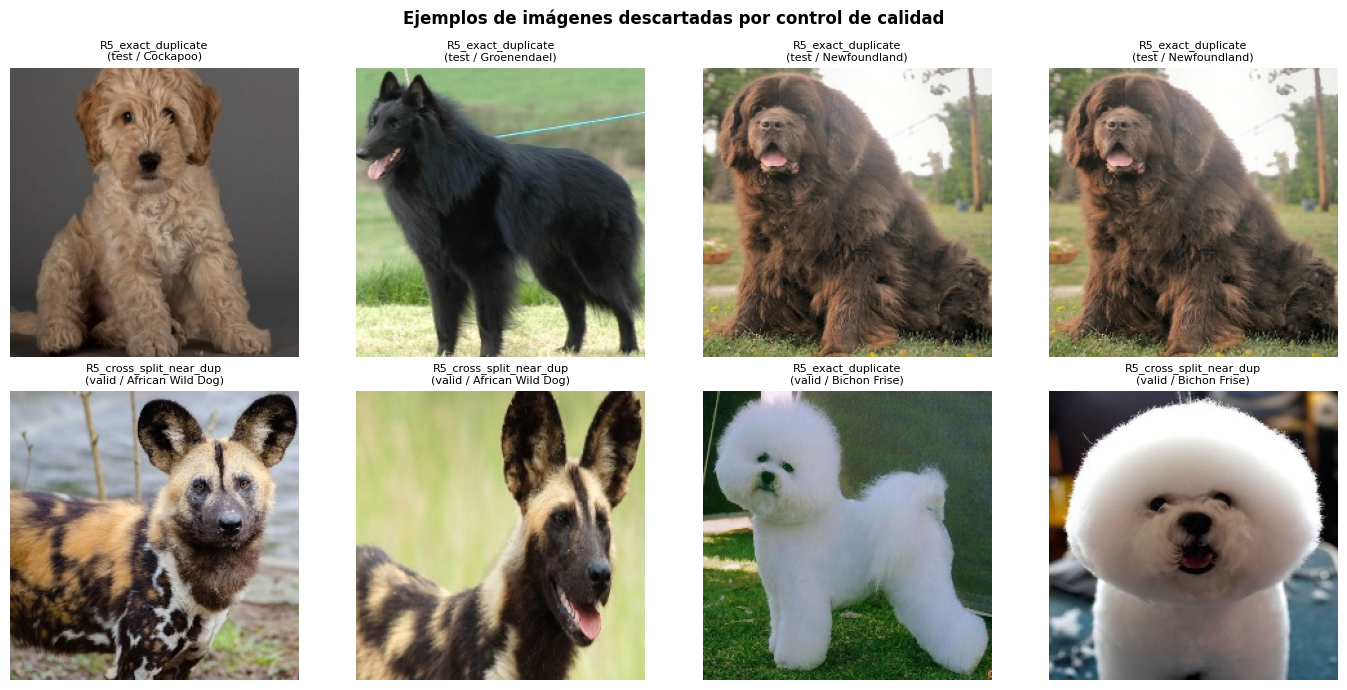

In [9]:
MIN_SIDE = 64
MIN_AR, MAX_AR = 0.25, 4.0
MIN_BRIGHTNESS, MAX_BRIGHTNESS = 15.0, 245.0
MIN_CONTRAST = 8.0
MIN_BLUR = 15.0
DHASH_MAX_DIST = 3  # bits de diferencia sobre 64 bits


def hamming_distance(h1: int, h2: int) -> int:
    return (h1 ^ h2).bit_count()


df_qc = df_eda.copy()
df_qc["discard_reason"] = None

# Regla 1: Corruptos
mask_r1 = df_qc["corrupt"] == True
df_qc.loc[mask_r1, "discard_reason"] = "R1_corrupt"

# Regla 2: Resolución / Aspect Ratio
mask_r2 = df_qc["discard_reason"].isna() & (
    (df_qc["width"] < MIN_SIDE)
    | (df_qc["height"] < MIN_SIDE)
    | (df_qc["aspect_ratio"] < MIN_AR)
    | (df_qc["aspect_ratio"] > MAX_AR)
)
df_qc.loc[mask_r2, "discard_reason"] = "R2_resolution_or_ar"

# Regla 3: Exposición extrema / imagen plana
mask_r3 = df_qc["discard_reason"].isna() & (
    (df_qc["brightness"] < MIN_BRIGHTNESS)
    | (df_qc["brightness"] > MAX_BRIGHTNESS)
    | (df_qc["contrast"] < MIN_CONTRAST)
)
df_qc.loc[mask_r3, "discard_reason"] = "R3_extreme_exposure"

# Regla 4: Desenfoque severo
mask_r4 = df_qc["discard_reason"].isna() & (df_qc["blur_score"] < MIN_BLUR)
df_qc.loc[mask_r4, "discard_reason"] = "R4_severe_blur"

# Regla 5: Duplicados exactos (SHA-256) y casi-duplicados (dHash), prioridad test -> valid -> train
split_priority = {"test": 0, "valid": 1, "train": 2}
df_qc["priority"] = df_qc["split"].map(split_priority)
df_qc = df_qc.sort_values(["priority", "rel_path"]).reset_index(drop=True)

seen_sha = set()
seen_dhashes: list[tuple[int, str, str]] = []  # (dhash, split, rel_path)

for idx, row in df_qc.iterrows():
    if pd.notna(row["discard_reason"]):
        continue
    sha = row["sha256"]
    dh = int(row["dhash"])

    if sha in seen_sha:
        df_qc.at[idx, "discard_reason"] = "R5_exact_duplicate"
        continue

    is_near_dup = False
    for prev_dh, prev_split, _ in seen_dhashes:
        if hamming_distance(dh, prev_dh) <= DHASH_MAX_DIST:
            is_near_dup = True
            reason = (
                "R5_cross_split_near_dup"
                if prev_split != row["split"]
                else "R5_within_split_near_dup"
            )
            df_qc.at[idx, "discard_reason"] = reason
            break

    if not is_near_dup:
        seen_sha.add(sha)
        seen_dhashes.append((dh, row["split"], row["rel_path"]))

# Reporte de descartes por regla y split
discarded_df = df_qc[df_qc["discard_reason"].notna()]
qc_report = (
    discarded_df.groupby(["discard_reason", "split"])
    .size()
    .unstack(fill_value=0)
)
qc_report["Total"] = qc_report.sum(axis=1)
print(f"Total imágenes analizadas : {len(df_qc)}")
print(f"Total imágenes descartadas: {len(discarded_df)}")
print(f"Total imágenes conservadas: {len(df_qc) - len(discarded_df)}")
display(qc_report)

# Visualizar ejemplos de imágenes descartadas (hasta 8)
if len(discarded_df) > 0:
    sample_disc = discarded_df.head(8)
    n_cols = min(4, len(sample_disc))
    n_rows = int(np.ceil(len(sample_disc) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.5 * n_rows))
    axes = np.atleast_1d(axes).flatten()
    for ax, (_, r) in zip(axes, sample_disc.iterrows()):
        img = cv2.imread(r["filepath"])
        if img is not None:
            ax.imshow(bgr_to_rgb(img))
        ax.set_title(f"{r['discard_reason']}\n({r['split']} / {r['breed']})", fontsize=8)
        ax.axis("off")
    for ax in axes[len(sample_disc):]:
        ax.axis("off")
    plt.suptitle("Ejemplos de imágenes descartadas por control de calidad", fontweight="bold")
    plt.tight_layout()
    plt.show()

## 8. Conjunto independiente de evaluación


Para evaluar la generalización fuera del dominio del dataset de Kaggle, se estructura el conjunto independiente en `data/dataset/independent/` con tres grupos:

- `data/dataset/independent/<raza>/`: imágenes externas de un solo perro etiquetadas con el nombre exacto de una de las 70 razas (se usan para evaluar Etapas 1, 2 y 3).
- `data/dataset/independent/_multi_dog/`: escenas con dos o más perros de razas conocidas (evaluación de detección múltiple y clasificación por recorte en Etapa 3).
- `data/dataset/independent/_no_dog/`: escenas urbanas, paisajes, personas u otros animales sin perros (evaluación de tasa de falsos positivos en Etapa 3).

Se genera además el manifiesto `data/independent_metadata.csv` donde se documenta fuente, licencia y ausencia de personas identificables. Esta carpeta está excluida del repositorio mediante `.gitignore`.

In [10]:
IMAGE_EXTS_IND = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".jfif"}
INDEPENDENT_DIR = DATASET_DIR / "independent"
(INDEPENDENT_DIR / "_multi_dog").mkdir(exist_ok=True)
(INDEPENDENT_DIR / "_no_dog").mkdir(exist_ok=True)

valid_breeds_set = set(df_qc["breed"].unique())
ind_records = []
corrupt_ind = []

for subdir in sorted(INDEPENDENT_DIR.iterdir()):
    if not subdir.is_dir():
        continue
    folder_name = subdir.name
    norm_name = normalize_breed_name(folder_name)

    if folder_name == "_multi_dog":
        scenario = "multi_dog"
        breed_label = "multi_dog"
    elif folder_name == "_no_dog":
        scenario = "no_dog"
        breed_label = "no_dog"
    else:
        assert norm_name in valid_breeds_set, (
            f"Carpeta '{folder_name}' en independent/ no coincide con ninguna de las 70 razas."
        )
        scenario = "single_dog"
        breed_label = norm_name

    for img_path in sorted(subdir.iterdir()):
        if not img_path.is_file() or img_path.suffix.lower() not in IMAGE_EXTS_IND:
            continue
        img_check = cv2.imread(str(img_path))
        if img_check is None or img_check.size == 0:
            corrupt_ind.append(str(img_path))
            continue
        h, w = img_check.shape[:2]
        ind_records.append(
            {
                "rel_path": img_path.relative_to(DATA_DIR).as_posix(),
                "scenario": scenario,
                "breed": breed_label,
                "width": int(w),
                "height": int(h),
                "source": "Unsplash",
                "license": "Unsplash License",
                "identifiable_persons": False,
            }
        )

assert len(corrupt_ind) == 0, f"Imágenes ilegibles en independent/: {corrupt_ind}"

df_independent = pd.DataFrame(ind_records)
ind_meta_path = DATA_DIR / "independent_metadata.csv"
df_independent.to_csv(ind_meta_path, index=False)

print(f"Total imágenes independientes válidas: {len(df_independent)}")
print("Desglose por escenario:", df_independent["scenario"].value_counts().to_dict())
print(
    "Razas distintas cubiertas (single_dog):",
    df_independent[df_independent["scenario"] == "single_dog"]["breed"].nunique(),
)

Total imágenes independientes válidas: 163
Desglose por escenario: {'single_dog': 118, 'no_dog': 30, 'multi_dog': 15}
Razas distintas cubiertas (single_dog): 60


## 9. Preprocesamiento

El preprocesamiento se encapsula en **`src/lib/preprocessing.py`** para garantizar consistencia total entre entrenamiento, validación, prueba e inferencia en la API:

1. **Orden de canales (`BGR -> RGB`):** OpenCV (`cv2.imread`) carga las imágenes en formato `BGR uint8`. `bgr_to_rgb()` convierte explícitamente a `RGB` antes de normalizar, evitando la inversión de canales rojo/azul que degradaría la representación de pelajes (ej. *Golden Retriever*, *Vizsla*, *Irish Spaniel*).
2. **Redimensionamiento (`Resize(224, 224)`):** Se redimensiona directamente a `224 × 224` píxeles (sin recorte central agresivo) porque tanto las fotos del dataset como los recortes generados por YOLO en la Etapa 3 ya vienen encuadrados alrededor del perro; un `CenterCrop` recortaría extremos diagnósticos de la raza como orejas erguidas/caídas o cola.
3. **Normalización (`IMAGENET_MEAN`, `IMAGENET_STD`):** Se escalan los píxeles a `[0, 1]` y se estandarizan con `mean=(0.485, 0.456, 0.406)` y `std=(0.229, 0.224, 0.225)`, alineando la distribución de entrada con los pesos pre-entrenados de ImageNet (`ResNet18`/`ResNet50`) y estabilizando el gradiente de la CNN custom.

In [11]:
sample_path = df_qc[df_qc["discard_reason"].isna()].iloc[0]["filepath"]
img_bgr = cv2.imread(sample_path)
tensor_out = preprocess_bgr_image(img_bgr, image_size=settings.image_size)

print("Imagen BGR entrada :", img_bgr.shape, img_bgr.dtype)
print("Tensor RGB salida  :", tuple(tensor_out.shape), tensor_out.dtype)
print(f"Rango tensor norm  : [{tensor_out.min():.3f}, {tensor_out.max():.3f}]")

Imagen BGR entrada : (224, 224, 3) uint8
Tensor RGB salida  : (3, 224, 224) torch.float32
Rango tensor norm  : [-2.118, 2.640]


## 10. Data augmentation


Se aplica exclusivamente sobre la partición `train` mediante `get_train_transforms()` (definido en `src/lib/preprocessing.py`):

- **`HorizontalFlip(p=0.5)`:** invariancia ante orientación izquierda/derecha del perro. No se usa flip vertical porque no refleja capturas reales.
- **`Rotate(limit=20, border_mode=BORDER_REFLECT_101, p=0.6)`:** tolerancia a inclinaciones de cámara y encuadres imperfectos de YOLO.
- **`RandomBrightnessContrast(±20%, p=0.6)` y `HueSaturationValue(hue=±8, sat=±15, val=±15, p=0.4)`:** variaciones moderadas de iluminación exterior/interior sin alterar el color base del pelaje al punto de confundir razas.
- **`OneOf([GaussianBlur(3..5), MotionBlur(3..5)], p=0.25)`:** robustez frente a desenfoque por movimiento del animal.
- **`GaussNoise(p=0.25)`:** tolerancia al ruido de sensor en cámaras web o fotos con poca luz.

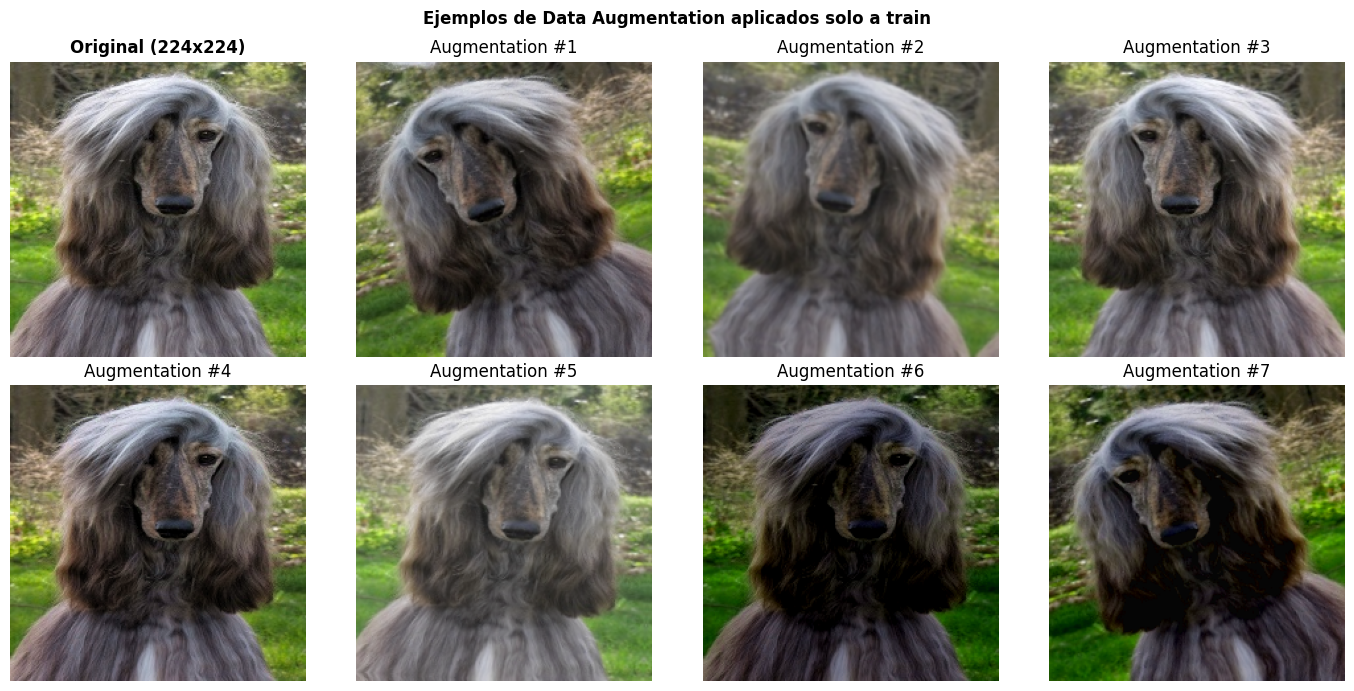

In [12]:
vis_aug = get_visual_augmentation_pipeline(image_size=settings.image_size)
img_rgb_orig = bgr_to_rgb(img_bgr)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

axes[0].imshow(cv2.resize(img_rgb_orig, (settings.image_size, settings.image_size)))
axes[0].set_title("Original (224x224)", fontweight="bold")
axes[0].axis("off")

for i in range(1, 8):
    aug_img = vis_aug(image=img_rgb_orig)["image"]
    axes[i].imshow(aug_img)
    axes[i].set_title(f"Augmentation #{i}")
    axes[i].axis("off")

plt.suptitle("Ejemplos de Data Augmentation aplicados solo a train", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 11. Splits

In [13]:
import json

df_clean = df_qc[df_qc["discard_reason"].isna()].copy()

# Mapeo determinístico ordenado alfabéticamente de las 70 clases
class_names = sorted(df_clean["breed"].unique())
assert len(class_names) == 70, f"Se esperaban 70 clases y se obtuvieron {len(class_names)}"
breed_to_idx = {b: idx for idx, b in enumerate(class_names)}
df_clean["label_idx"] = df_clean["breed"].map(breed_to_idx)

# Verificación estricta de ausencia de fuga de datos entre splits
train_hashes = set(df_clean[df_clean["split"] == "train"]["sha256"])
valid_hashes = set(df_clean[df_clean["split"] == "valid"]["sha256"])
test_hashes = set(df_clean[df_clean["split"] == "test"]["sha256"])

assert len(train_hashes & valid_hashes) == 0, "Fuga detectada entre train y valid!"
assert len(train_hashes & test_hashes) == 0, "Fuga detectada entre train y test!"
assert len(valid_hashes & test_hashes) == 0, "Fuga detectada entre valid y test!"
print("Verificación de fuga de datos: OK (0 hashes compartidos entre train, valid y test).")

# Exportar splits finales (CSV y JSON) + diccionario de clases para 2-train.ipynb y servicios
export_cols = ["rel_path", "breed", "label_idx", "split", "width", "height", "sha256"]
splits_csv_path = DATA_DIR / "splits.csv"
splits_json_path = DATA_DIR / "splits.json"
classes_json_path = DATA_DIR / "classes.json"

df_clean[export_cols].to_csv(splits_csv_path, index=False)
splits_json_path.write_text(
    json.dumps(df_clean[export_cols].to_dict(orient="records"), indent=2, ensure_ascii=True),
    encoding="utf-8",
)
classes_json_path.write_text(
    json.dumps({"classes": class_names, "breed_to_idx": breed_to_idx}, indent=2, ensure_ascii=True),
    encoding="utf-8",
)

print(f"Splits guardados en:\n  - {splits_csv_path}\n  - {splits_json_path}\n  - {classes_json_path}")

Verificación de fuga de datos: OK (0 hashes compartidos entre train, valid y test).
Splits guardados en:
  - c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\splits.csv
  - c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\splits.json
  - c:\Users\nicod\Desktop\TUIA\Vision por Computadora\tuia-dog-recognition-app\data\classes.json


## 12. Resumen final

Tabla con la cantidad de razas e imágenes por split, incluido el conjunto independiente.

In [14]:
rows_summary = []
for sp in ["train", "valid", "test"]:
    sub_raw = df_qc[df_qc["split"] == sp]
    sub_clean = df_clean[df_clean["split"] == sp]
    rows_summary.append(
        {
            "Partición": sp,
            "Razas": sub_clean["breed"].nunique(),
            "Imágenes originales": len(sub_raw),
            "Descartadas (QC)": len(sub_raw) - len(sub_clean),
            "Imágenes finales": len(sub_clean),
        }
    )

rows_summary.append(
    {
        "Partición": "independent (externo)",
        "Razas": (
            df_independent[df_independent["scenario"] == "single_dog"]["breed"].nunique()
            if len(df_independent) > 0
            else 0
        ),
        "Imágenes originales": len(df_independent),
        "Descartadas (QC)": 0,
        "Imágenes finales": len(df_independent),
    }
)

summary_final_df = pd.DataFrame(rows_summary)
display(summary_final_df)

,Partición,Razas,Imágenes originales,Descartadas (QC),Imágenes finales
0,train,70,7946,216,7730
1,valid,70,700,13,687
2,test,70,700,4,696
3,independent (externo),60,163,0,163


## 13. Licencias y uso de imágenes

- **Dataset principal (`70 Dog Breeds Image Dataset`):** Disponible en Kaggle bajo licencia **CC0: Public Domain**, habilitado para uso académico y de investigación sin restricciones de redistribución.
- **Conjunto independiente (`data/dataset/independent/`):** Compuesto por fotografías de dominio público y licencias abiertas de **Unsplash License**
- **Privacidad y criterio sobre personas identificables:** En cumplimiento de criterios de minimización de datos personales, se seleccionaron imágenes centradas en los animales sin rostros humanos identificables.